# Homework 4: Diffusion Models

## Google Colab [Optional]

If you are using Google Colab, configure and run the cell below to mount your Google Drive and set up the correct working directory for the assignment. You may ignore this cell if you are working locally.

In [ ]:
from google.colab import drive
import os

# 1. Mounting Google Drive: This allows Colab to access files in your Google Drive
drive.mount('/content/drive')

# 2. Tell Colab where to find your assignment files and where to save your work

# TODO: Enter the relative path in your Google Drive of the assignment.
FOLDERNAME = "Deep Learning Homework/hw4_code"

assert FOLDERNAME is not None, "[!] Enter the foldername."

FULL_PATH = "/content/drive/MyDrive/" + FOLDERNAME
assert os.path.exists(FULL_PATH), "Make sure your FOLDERNAME is correct"

In [ ]:
%cd $FULL_PATH

In [ ]:
# Uncomment and run on Google Colab. You may need to restart your session after running it.
!pip install zarr
!pip install pymunk
!pip install "nbconvert[webpdf]"

In [4]:
# Uncomment and run for local environment setup only. Do not run this if you are on Google Colab.
# !uv pip install -r requirements.txt

# Diffusion Models

Denoising Diffusion Probabilistic Models (DDPM) - https://arxiv.org/abs/2006.11239/ \
Classifier Free Guidance (CFG) - https://arxiv.org/abs/2207.12598

In this part of the assignment you will be implementing a diffusion model and applying it in two different domains - an image generation task and a robotics task.  Denoising Diffusion Probabilistic Models (DDPMs), also known as Diffusion Models, are state of the art generative models that train a network to itteratively denoise random gaussian noise.  If you have not done so already, please read through the DDPM paper linked above in order to get an understanding of the math behind DDPMs.  The code for this part of the assignment is not particularly difficult, but you will have a difficult time if you do not understand the theory behind diffusion models.  You will also be implementing classifier free guidance (CFG).  While the CFG paper does not have to be read as thoroughly as the DDPM paper, it is definitely a useful read if you are not familiar with CFG.

#### Creating the DDPM

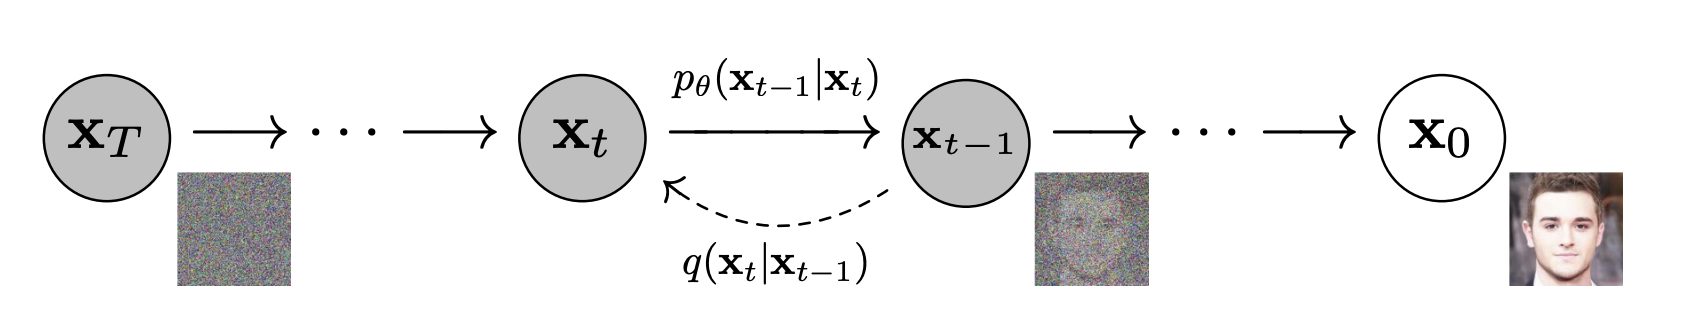

For the sake of this assignment, we are breaking the Diffusion Model into two parts.  A noise scheduler and a noise prediction net.  The noise scheduler handles the noise addition during the forward process and the noise removal during the reverse process.  The noise prediction net is a neural network that predicts the amount of noise that should be removed at each denoising step.  Transformers, like the one you implemented in the last assignment, can be used as this noise prediction network.  For this assignment we are using a U-Net as opposed to a transformer, but you will not be implementing this model, just training it.

### IMPORTANT NOTE FOR IMPLEMENTATION!

You will be generating random numbers in various sections of this project.  To keep the outputs deterministic for unit test and auto grader purposes, you <u>must</u> use our prebuilt randomizer function.  This randomizer is defined in ```randomizer.py```.  Please take a look at that function before you start coding.  The function that we define is sufficient for generating any random numbers that you will need for this project.    Do not worry about passing in seeds for the robotics section (2.4)

### IMPORTANT NOTE 2
The equations in the DDPM paper describe an unconditional model, you will be implementing a conditional model.  This does not significantly change the equations, you just need to pass in the conditioning term along with $x$ and $t$.  Make sure to watch the first lecture on generative models if you are running into confusion about this or other aspects of Diffusion Models.

## Part 2.1 - Noise Scheduler
### 2.1.1 - Forward Process (Adding Noise)

During the forward process, we take an input and gradually add Gaussian noise to the data according to a variance schedule.  This is described in section 2, background, of the DDPM paper.  You must read that section to complete this part of the assignment.


**TODO:** Complete initialization function in ```noise_scheduler.py```

**TODO:** Implement ``add_noise`` function in ``noise_scheduler.py``
\
\
_Hint:_ Pay attention to equation 4

In [5]:
# test initialization
!python -m pytest -s tests.py::TestCases::test_noise_scheduler_init
# test add noise
!python -m pytest -s tests.py::TestCases::test_add_noise

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0
rootdir: /content/drive/MyDrive/Deep Learning Homework/hw4_code
plugins: zarr-3.4.2, typeguard-4.6.0, langsmith-0.14.13, anyio-4.15.1, platformdirs-4.13.6
collected 1 item                                                               

tests.py NoiseScheduler() initialization test case passed!
.

============================== 1 passed in 26.69s ==============================
============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0
rootdir: /content/drive/MyDrive/Deep Learning Homework/hw4_code
plugins: zarr-3.4.2, typeguard-4.6.0, langsmith-0.14.13, anyio-4.15.1, platformdirs-4.13.6
collected 1 item                                                               

tests.py add_noise() test case passed!
.

============================== 1 passed in 15.49s =========

### 2.1.2 - Reverse Process (Removing Noise)

When taking a step during the backwards process, we have access to a partially noised sample $x_t$, the denoising timestep $t$, and our model's noise prediction.  We remove the predicted noise to get a slightly less noisy sample $x_{t-1}$.  The completely uncorrupted sample is recovered at $x_0$.  This process is described in detail in section 3 of the DDPM paper, please read this section before completing this part of the assignment.

*TODO:* Implement ``denoise_step`` function in ``noise_scheduler.py`` (do not implement the thresholding part yet)
\
\
_Hint:_ Pay attention to algorithm 2 - Sampling

In [6]:
# test denoise step
!python -m pytest -s tests.py::TestCases::test_denoise_step

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0
rootdir: /content/drive/MyDrive/Deep Learning Homework/hw4_code
plugins: zarr-3.4.2, typeguard-4.6.0, langsmith-0.14.13, anyio-4.15.1, platformdirs-4.13.6
collected 1 item                                                               

tests.py denoise_step() test case passed!
.

============================== 1 passed in 11.71s ==============================


## Part 2.2 - Constructing the Diffusion Model

We have provided you with a noise prediction network, and you have just written a noise scheduler.  With these two parts you are able to put together a completed diffusion model.

### 2.2.1 Compute Loss for Training

For this part of the assignment, you will be implementing the ``compute_loss_on_batch`` function of the diffusion model.  We have implemented the rest of the training logic for you. Keep in mind, the only part of the diffusion model that needs to be trained is the noise prediction network.  Your loss function should capture how well the noise_pred_net estimates the added noise.  We expect you to implement the simplified variant of the variational lower bound as described in section 3.4 of the DDPM paper.

*TODO:* Implement loss computation section of ``compute_loss_on_batch`` function in ``diffusion_model.py``
\
\
_Hint:_ Use your noise scheduler, refer to equation 14 and Algorithm 1 - Training
\
_Hint:_ For each item in the batch, you should be selecting a random timestep $t$ to compute the loss

In [7]:
# test loss computation
!python -m pytest -s tests.py::TestCases::test_compute_loss_on_batch

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0
rootdir: /content/drive/MyDrive/Deep Learning Homework/hw4_code
plugins: zarr-3.4.2, typeguard-4.6.0, langsmith-0.14.13, anyio-4.15.1, platformdirs-4.13.6
collected 1 item                                                               

tests.py compute_loss_on_batch() test case passed!
.

============================== 1 passed in 10.73s ==============================


### 2.2.2 Classifier Free Guidance

We want our diffusion model to make use of classifier free guidance.  If you are not familiar with classifier free guidance, please take a look at the CFG paper now.  Classifier free guidance allows us to variably combine noise predictions from a conditional and an unconditional noise prediction network at inference time.  This has the effect of enhancing class specific features and is critical for high quality image generation.  In practice, we train the unconditional noise prediction net at the same time as the conditional noise prediction net.  Section 3.2 of the CFG paper describes this process.  

<u>We expect you to use 0s as the null tokens. </u>
\
\
*TODO:* Implement classifier free guidance section of ``compute_loss_on_batch`` function in ``diffusion_model.py``
\
\
_Hint:_ This should only be a few lines, use self.p_uncond

In [8]:
# test classifier free guidance training
!python -m pytest -s tests.py::TestCases::test_compute_loss_with_cfg

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0
rootdir: /content/drive/MyDrive/Deep Learning Homework/hw4_code
plugins: zarr-3.4.2, typeguard-4.6.0, langsmith-0.14.13, anyio-4.15.1, platformdirs-4.13.6
collected 1 item                                                               

tests.py compute_loss_with_cfg() test case passed!
.

============================== 1 passed in 10.45s ==============================


### 2.2.3 Sample Generation (with classifier free guidance)

Before we can actually use our diffusion model, we need to write the code for generating a sample.  To generate an output, we draw a sample $x_T$ from random gaussian noise.  We then itteratively denoise the random output for T denoising timesteps until we get our uncorrupted output $x_0$.  You will be implementing sampling with classifier-free guidance.  Do not worry about replicating algorithm 2 of the CFG paper, we only expect you to calculate the updated noise prediction from equation 6 of the CFG paper:$$ \bar{\epsilon_\theta}(x_t, t, c) = (1 + w) * \epsilon_\theta(x_t, t, c) - w * \epsilon_\theta(x_t, t, \empty) $$

where $\epsilon_\theta$ is the predicted noise from your noise prediction network and $w$ is the guidance weight

*TODO:* Implement ``generate_sample`` function in ``diffusion_model.py``
\
\
_Hint:_ Use your noise scheduler and refer to Algorithm 2 - Sampling of the DDPM paper \
_Hint:_ Dont forget that this is a conditional model and to include classifier free guidance

In [9]:
# test generate sample
!python -m pytest -s tests.py::TestCases::test_generate_sample

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0
rootdir: /content/drive/MyDrive/Deep Learning Homework/hw4_code
plugins: zarr-3.4.2, typeguard-4.6.0, langsmith-0.14.13, anyio-4.15.1, platformdirs-4.13.6
collected 1 item                                                               

tests.py generate_sample_step() test case passed!
generate_sample_step() with guidance test case passed!
.

============================== 1 passed in 13.68s ==============================


## Part 2.3 - Diffusion Model Applications (Computer Vision)

Diffusion models are mostly known in popular culture because of image generation tools such as Dall-e and Midjourney.  These models are able to take in text based prompts and output extremely realistic photos.  For the sake of this assignment we will not be implementing anything that is nearly as visually impressive, but we hope to shed some insight on a few critical aspects to state of the art diffusion models.  Namely classifier free guidance and thresholding.  You will be working with a subset of the CIFAR-10 dataset.  The CIFAR-10 dataset consists of 60000 32x32 color images in 10 classes, with 6000 images per class.  We will be working with the first three classes of this dataset - airplanes, automobiles, and birds.

<!-- <img src="assets/CIFAR.png" alt="CIFAR" style="width:500px" /> -->

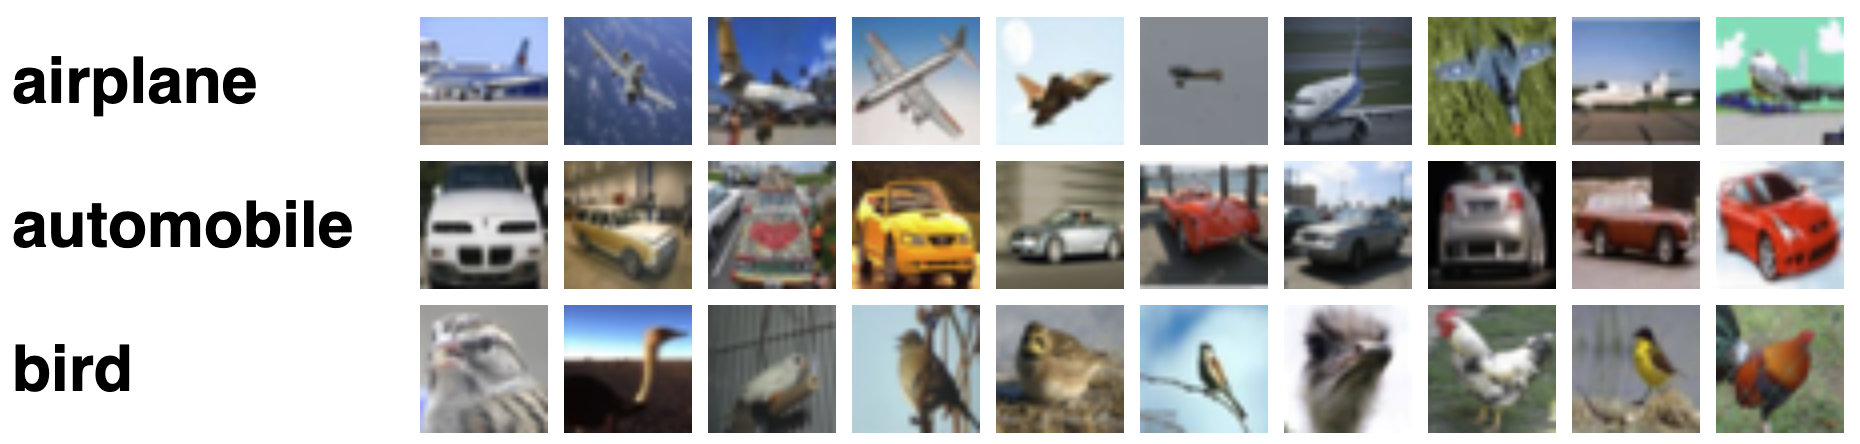

In [10]:
# Imports and global function definitions
from computer_vision.image_gen import ImageGenerator
from matplotlib import pyplot as plt

def plot_image(output):
    B, H, W, C = output.shape
    # batch size divided by number of classes
    num_cols = B // 3
    assert B % 3 == 0
    fig, axes = plt.subplots(3, num_cols, figsize=(12, 8))
    # Loop through the rows
    for i in range(3):
        # Loop through the columns
        for j in range(B // 3):
            image = output[i * (B // 3) + j]
            if num_cols == 1:
                axes[i].imshow(image)
                axes[i].axis('off')
            else:
                axes[i, j].imshow(image)
                axes[i, j].axis('off')

    # label the first row "airplane", the second row "automobile", and the third row "bird"
    axes[0, 0].set_title('airplane')
    axes[1, 0].set_title('automobile')
    axes[2, 0].set_title('bird')

    plt.show()


# If you are facing numpy and scipy comptability issues on google colab after running the cells below,
# e.g ImportError: cannot import name '_center' from 'numpy._core.umath'
# please restart your session after running this cell to clear old packages from memory and enforce the compatible versions.

In [23]:
# Run this cell to download the dataset, only needs to be done once even if you restart the notebook
!python ./collect_data.py

CIFAR-10: 100% 170M/170M [33:54<00:00, 83.8kiB/s]
Download complete.
Extracting computer_vision/cifar-10-python.tar.gz...
/content/drive/MyDrive/Deep Learning Homework/hw4_code/./collect_data.py:38: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=download_dir)
Extraction complete.
Removing computer_vision/cifar-10-python.tar.gz.
Cleanup complete.


### 2.3.1 Image Generation and Classifier Free Guidance

Now it is time to train the model - if this fails to run, go and check over your previous work.
We are implementing a small model, but even still, this will take a while to train!  Please use Colab if you do not have access to a GPU.  The remainder of this assignment will be infeasable for you if you do not have a GPU.  That being said, we understand that you have time constraints and we do not expect you to let this model train for hours (although your results would look much better if you did).

We ask that you budget 30 minutes for the training of this image generation model, you can run it for longer if you prefer though.  Do not stress too much about the specific images generated, we know the outputs will be poor given your limited computation budget.  If your loss isnt decreasing (should get below 0.1 after ~7 epochs of training and below 0.05 by the end of training) or you are generating random noise, then you may have a serious issue.  But if your airplane is a smudge on a blue-ish background, that is a great output.  The goal is for you to learn, we will be paying much more attention to your analysis than your images.  

In [12]:
generator = ImageGenerator()

In [13]:
generator.load_dataset(dataset_paths=[
    'computer_vision/cifar-10-batches-py/data_batch_1',
    'computer_vision/cifar-10-batches-py/data_batch_2',
    'computer_vision/cifar-10-batches-py/data_batch_3',
    'computer_vision/cifar-10-batches-py/data_batch_4',
    'computer_vision/cifar-10-batches-py/data_batch_5',
    ], batch_size = 64
     )

In [14]:
# You can just rerun this cell to keep training the model

# Keep the number of epochs at 25 for now (if you need it to be smaller that is okay as well)
# You will have a chance to increase the training time and generate your best images at the end of this section
generator.train_policy(epochs=25)
generator.policy.save_weights('model_pths/image_weights.pth')

# Load the model from the checkpoint
# generator.policy.load_weights('model_pths/image_weights.pth')
# generator.load_dataset(dataset_paths=[
#     'computer_vision/cifar-10-batches-py/data_batch_1',
#     'computer_vision/cifar-10-batches-py/data_batch_2',
#     'computer_vision/cifar-10-batches-py/data_batch_3',
#     'computer_vision/cifar-10-batches-py/data_batch_4',
#     'computer_vision/cifar-10-batches-py/data_batch_5',
#     ], batch_size = 64
#      )


Batch: 100%|██████████| 235/235 [00:50<00:00,  4.65it/s]

Batch: 100%|██████████| 235/235 [00:54<00:00,  4.28it/s]

Batch: 100%|██████████| 235/235 [00:53<00:00,  4.43it/s]

Batch: 100%|██████████| 235/235 [00:53<00:00,  4.37it/s]

Batch: 100%|██████████| 235/235 [00:53<00:00,  4.41it/s]

Batch: 100%|██████████| 235/235 [00:53<00:00,  4.37it/s]

Batch: 100%|██████████| 235/235 [00:53<00:00,  4.40it/s]

Batch: 100%|██████████| 235/235 [00:53<00:00,  4.36it/s]

Batch: 100%|██████████| 235/235 [00:53<00:00,  4.36it/s]

Batch: 100%|██████████| 235/235 [00:53<00:00,  4.36it/s]

Batch: 100%|██████████| 235/235 [00:53<00:00,  4.37it/s]

Batch: 100%|██████████| 235/235 [00:53<00:00,  4.36it/s]

Batch: 100%|██████████| 235/235 [00:53<00:00,  4.37it/s]

Batch: 100%|██████████| 235/235 [00:53<00:00,  4.37it/s]

Batch: 100%|██████████| 235/235 [00:53<00:00,  4.38it/s]

Batch: 100%|██████████| 235/235 [00:53<00:00,  4.38it/s]

Batch: 100%|██████████| 235/235 [00:53<00:00,  4.38it/s]

Batch: 100%|█

### Image Generation (without Thresholding) [1 point]
First, you will evaluate the output of unguided image generation.  The generate_images will produce num_samples generations of each class. Assign the generated images to the corresponding question in Gradescope.

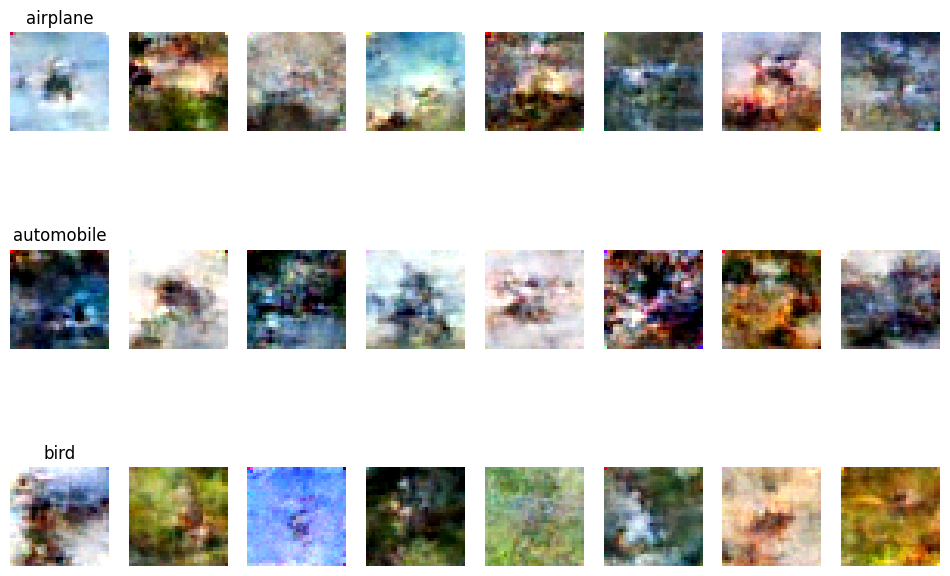

In [15]:
image = generator.generate_images(guidance=0, num_samples=8)
plot_image(image)

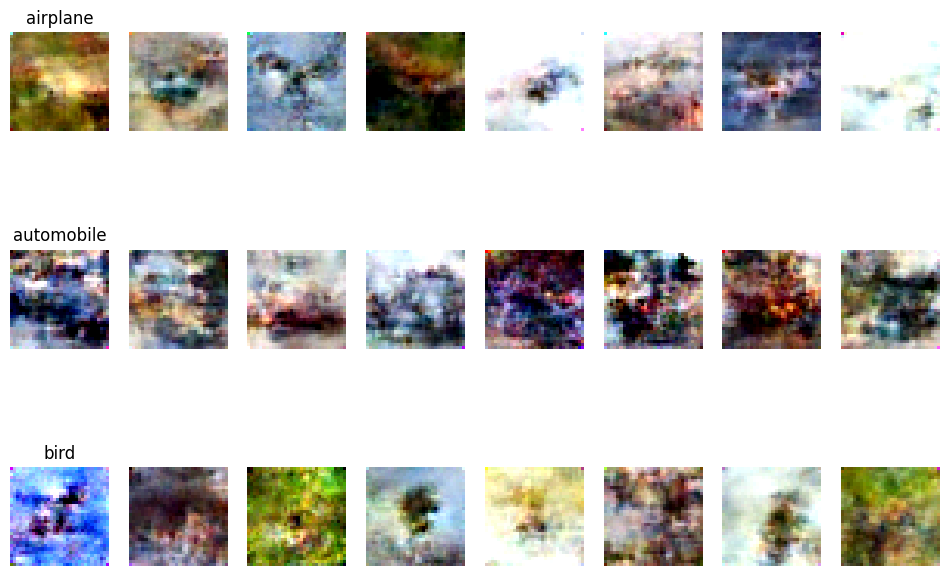

In [16]:
image = generator.generate_images(guidance=0.5, num_samples=8)
plot_image(image)

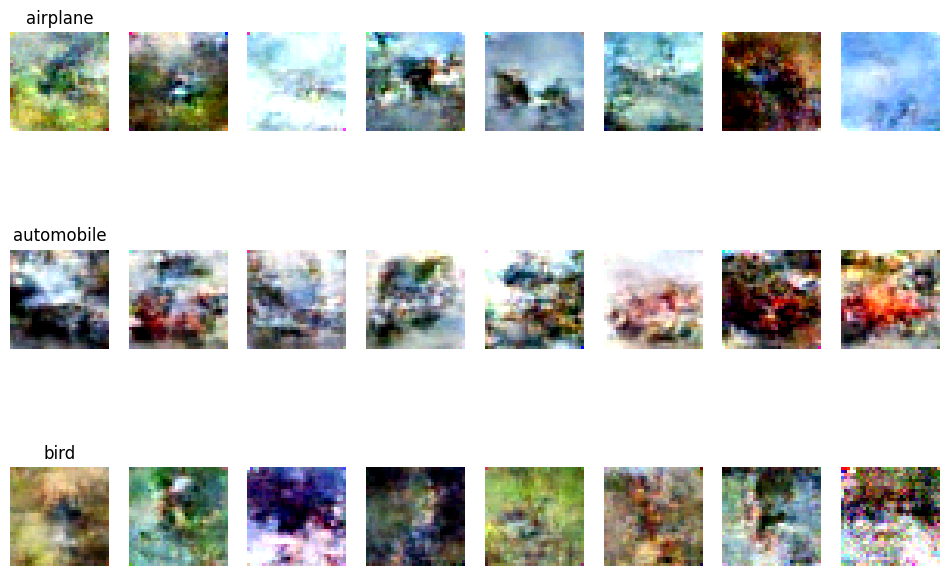

In [17]:
image = generator.generate_images(guidance=1, num_samples=8)
plot_image(image)

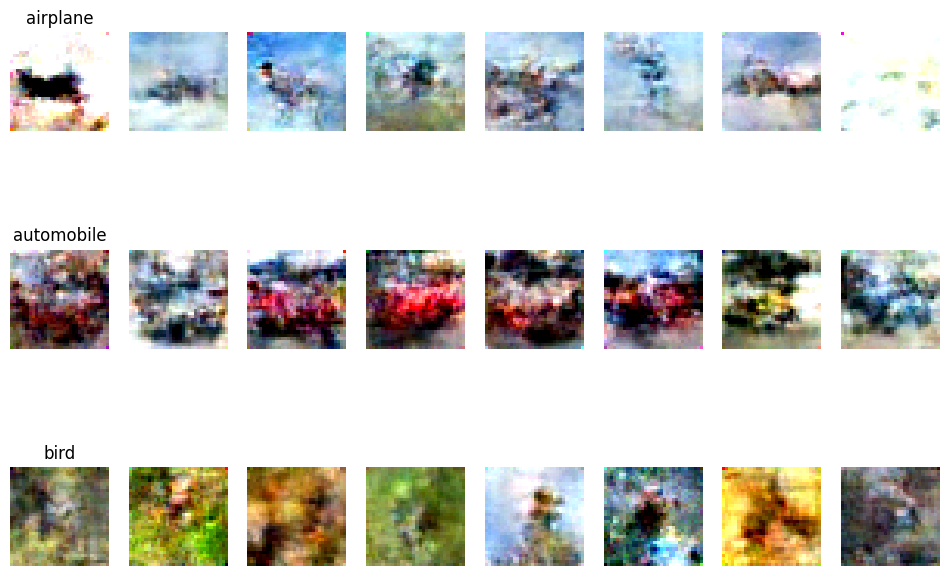

In [18]:
image = generator.generate_images(guidance=2, num_samples=8)
plot_image(image)

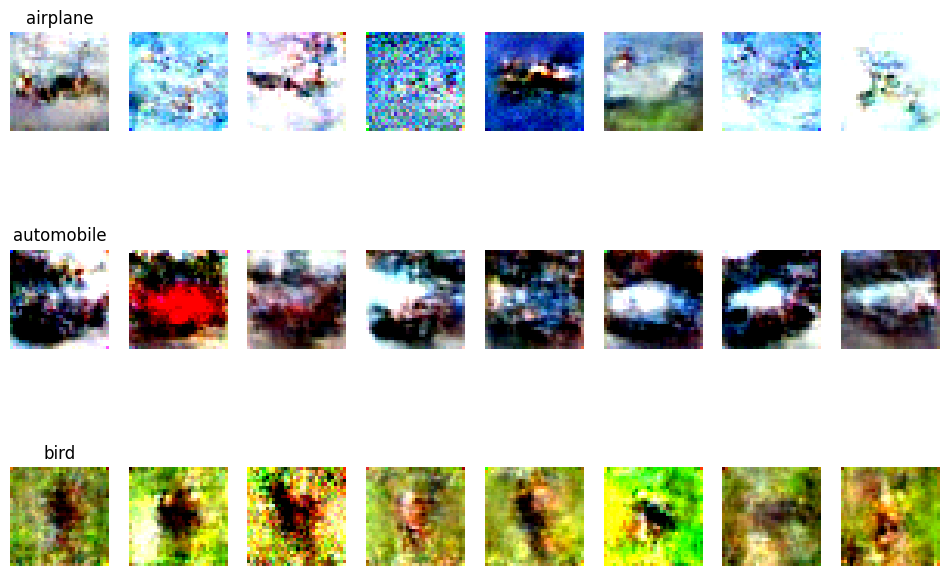

In [19]:
image = generator.generate_images(guidance=5, num_samples=8)
plot_image(image)

### 2.3.2 Thresholding

You may have noticed that with high guidance weights, the images tend to oversaturate.  This is because the model is predicting values outside of the range [-1, 1] (our input is normalized to this range before being passed to the model).  To help mitigate this, it is common to threshold sample predictions at each denoising step.  As our denoising step is currently implemented, we can't actually use this technique. This is because we directly estimate $x_{t-1}$.  

So we need to compute $x_{t-1}$ such that we estimate $x_{0}$ as an intermediate step.  This way we can threshold our estimate of $x_{0}$.  
<u> This is shown in equations (6) and (7) of the DDPM paper.  The equation for computing an estimate of $x_0$ is shown in equation (15).  Make sure to threshold the prediction of $x_0$! </u>

*TODO:* Implement denoising with thresholding in the ``denoise_step`` function in ``noise_scheduler.py``

In [20]:
# test denoise step with thresholding
!python -m pytest -s tests.py::TestCases::test_threshold_denoise_step

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0
rootdir: /content/drive/MyDrive/Deep Learning Homework/hw4_code
plugins: zarr-3.4.2, typeguard-4.6.0, langsmith-0.14.13, anyio-4.15.1, platformdirs-4.13.6
collected 1 item                                                               

tests.py threshold_denoise_step() test case passed!
.

============================== 1 passed in 10.76s ==============================


### Image Generation (with Thresholding) [1 point]
Now that you have completed the thresholding, evaluate how this changes image generation with different guidance weights. Assign the generated images to the corresponding question in Gradescope.

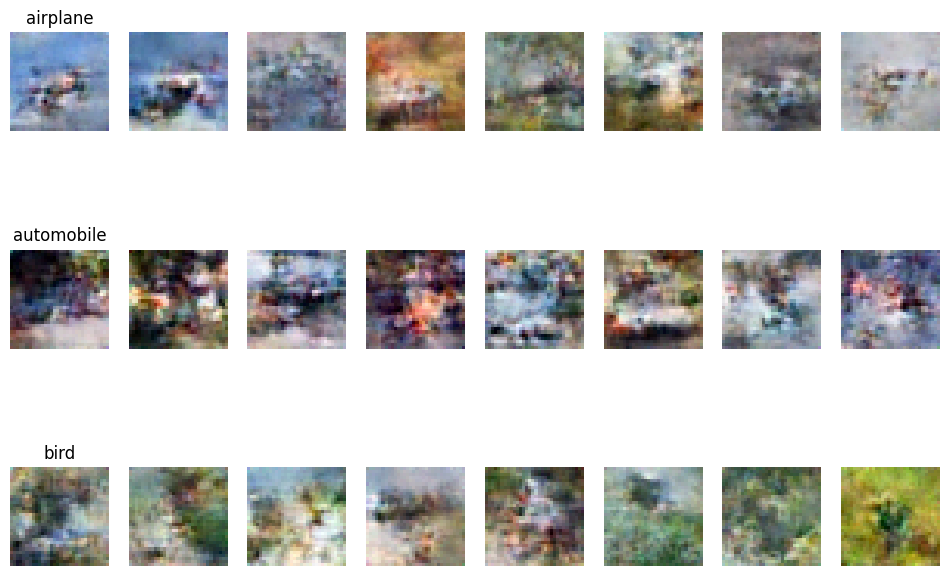

In [21]:
image = generator.generate_images(guidance=0, num_samples=8, threshold=True)
plot_image(image)

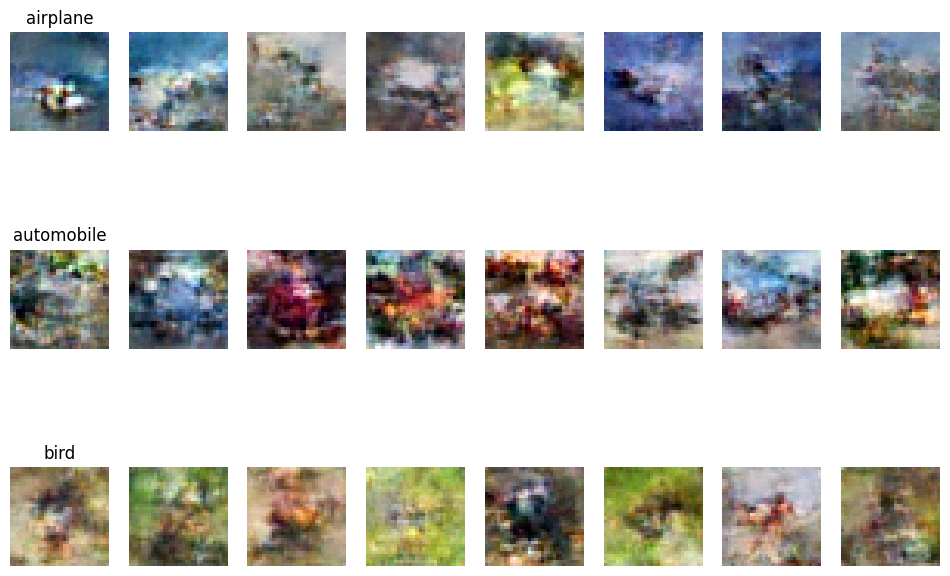

In [22]:
image = generator.generate_images(guidance=0.5, num_samples=8, threshold=True)
plot_image(image)

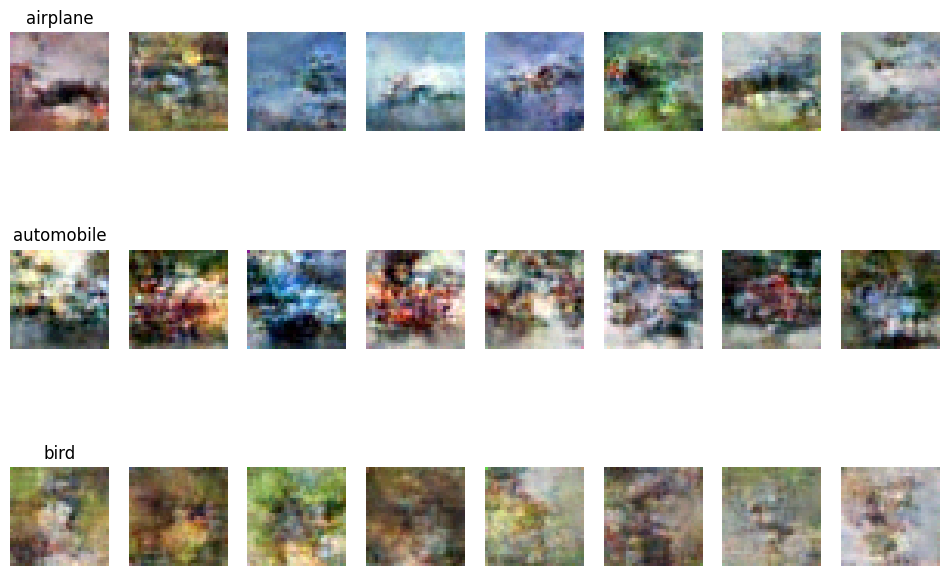

In [23]:
image = generator.generate_images(guidance=1, num_samples=8, threshold=True)
plot_image(image)

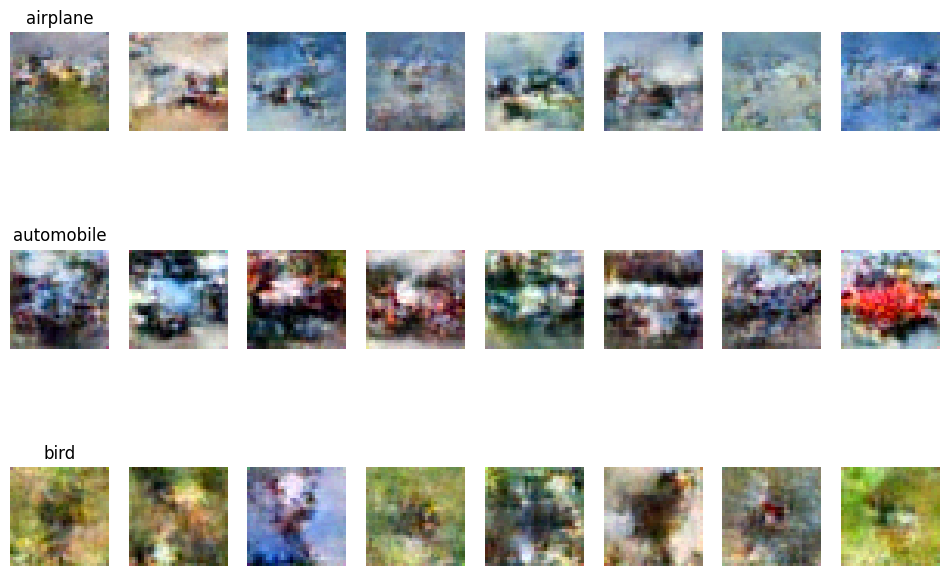

In [24]:
image = generator.generate_images(guidance=2, num_samples=8, threshold=True)
plot_image(image)

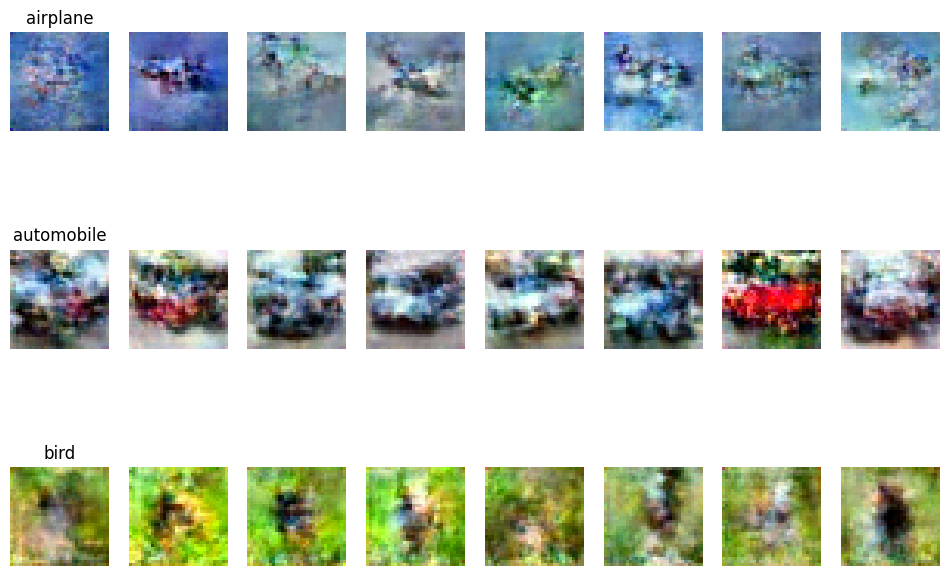

In [25]:
image = generator.generate_images(guidance=5, num_samples=8, threshold=True)
plot_image(image)

Feel free to experiment with different training times and guidance weights!  Try and get the best image possible (or show something else interesting).

In [ ]:
# room for experimentation

## Part 2.4 - Diffusion Model Applications (Robotics) [Extra Credit - 5 points]

Diffusion models are frequently used in the image generation domain, but they are also very effective policy generators.  In the context of deep learning for robotics, we think of a policy $\pi(a | s)$ as a deep neural network that models the action, $a$, an agent can take given it's current state, $s$ (its current observation of the world).  Lets assume we have access to a set of demonstrations $D = \{\tau_i\}^N_{i=1}$ where each $\tau_i$ is a trajectory such that $\tau_i = \{s_n, a_n\}^{len(\tau_i)}_n$.  That is to say, our demonstration dataset will contain a set of states and the corresponding actions that our agent has taken from those states.  If we train a policy to model this distribution of actions given the current state, then we should be able to imitate what was demonstrated.  For this project, we will be using a diffusion model as our policy.  Here are some papers that have used diffusion models as robot policies if you are interested in reading more (you are not required to read these papers to complete this section of the project):

Diffuser - https://arxiv.org/abs/2205.09991 \
Decision Diffuser - https://arxiv.org/abs/2211.15657 \
Diffusion Policy - https://arxiv.org/abs/2303.04137

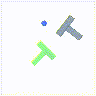

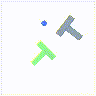

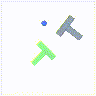

In [26]:
from IPython.display import Image, display
display(Image(filename='./assets/demo1.gif'))
display(Image(filename='./assets/demo2.gif'))
display(Image(filename='./assets/demo3.gif'))

### Push-T Demonstration Dataset

We will be using a dataset of demonstrations where a point agent pushes a T-shaped block onto a T-shaped outline.  A visualization of a few of these demonstrations is shown above.  Here we will define a few characteristics of the dataset.

Dataset Characteristics:
- Total Demonstrations = 206
- Maximum Demonstration Length = 246 timesteps
- Action Dimension = 2 (agent_x, agent_y)
- State Dimension = 5 (agent_x, agent_y, block_x, block_y, block_rotation)
- Reward = fraction of T-shaped outline covered by T-shaped block (min = 0, max = 1)

In [27]:
import os
import gdown
import zipfile

# Download the dataset
dataset_path = "robotics/push_t_dataset.zarr"
zip_path = "robotics/push_t_dataset.zarr.zip"
if not os.path.isfile(dataset_path):
    id = "1KY1InLurpMvJDRb14L9NlXT_fEsCvVUq&confirm=t"
    gdown.download(id=id, output=zip_path, quiet=False)

    # unzip the downloaded file
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(dataset_path)

    os.remove(zip_path)


Downloading...
From: https://drive.google.com/uc?id=1KY1InLurpMvJDRb14L9NlXT_fEsCvVUq&confirm=t
To: /content/drive/MyDrive/Deep Learning Homework/hw4_code/robotics/push_t_dataset.zarr.zip
100%|██████████| 31.1M/31.1M [00:00<00:00, 65.2MB/s]


### 2.4.1 Constructing the Training Dataset

In order to train the diffusion model, we need to get our demonstrations in the correct format.  Remember, our goal is for the diffusion model to learn $q(a|s)$, the distribution of actions given the current state.  So the model inputs are actions and the conditioning terms are states.  Naively, we would turn a demonstration of length L into L different data points.  Each datapoint would have one action and one state that it is conditioned on.

In practice, we do not predict one action at a time, we predict a sequence of actions.  This is known as [action chunking](https://arxiv.org/abs/2304.13705) in the robotics literature.  Additionally, it is common to condition on multiple previous states, not just the current state (we can't condition on future states because they haven't happened yet).  For this assignment, we want the diffusion model to be conditioned on $H_s$ states and we want the model to generate $H_a$ actions at a time ($H_s < H_a$).


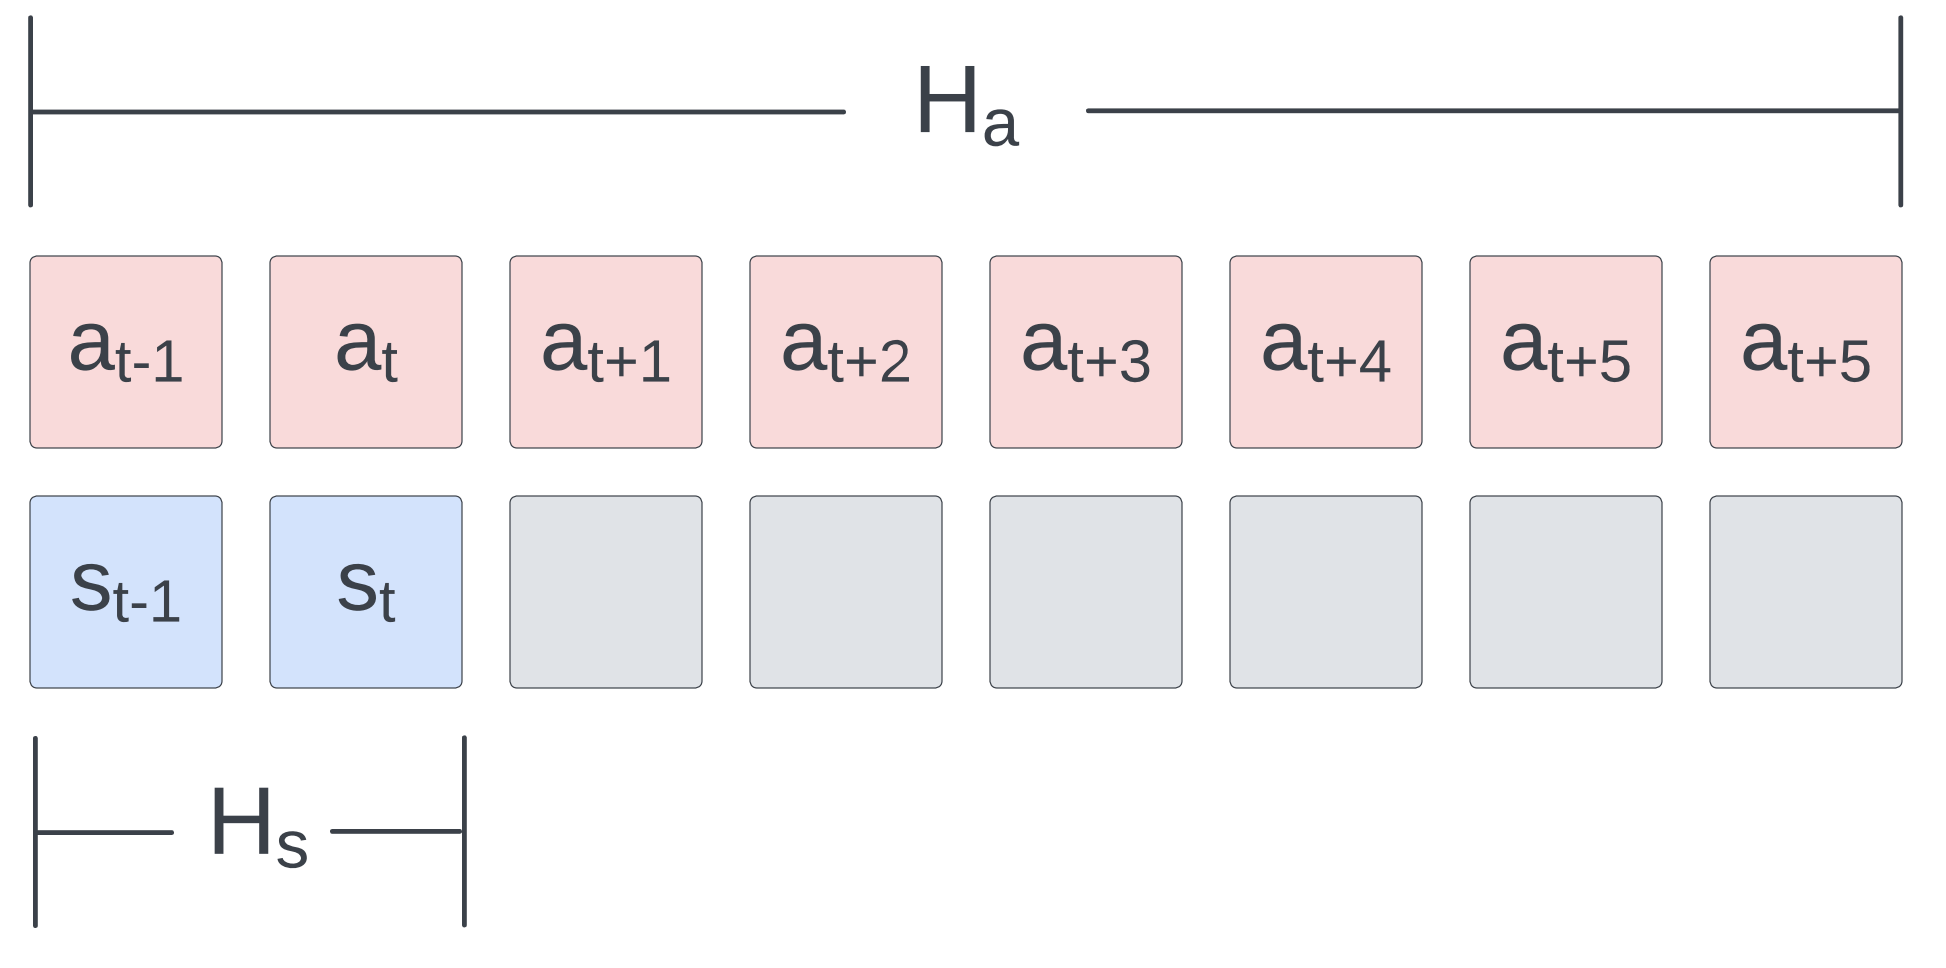

But what if we are at the beginning of a demonstration where $s_{0-x}$ and $a_{0-x}$ do not exist?  Then you should repeat $s_0$ and $a_0$ for the appropriate number of times.  
What if we are at the end of a demonstation where future states and actions do not exist?  Then you should repeat the final values for the appropriate number of times.

*TODO:* Complete the ``load_dataset`` function in ``robotics/dataset.py``

In [28]:
# test load dataset
!python -m pytest -s tests.py::TestCases::test_robotics_dataset

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0
rootdir: /content/drive/MyDrive/Deep Learning Homework/hw4_code
plugins: zarr-3.4.2, typeguard-4.6.0, langsmith-0.14.13, anyio-4.15.1, platformdirs-4.13.6
collected 1 item                                                               

tests.py PushTDataset() test case passed!
.

============================== 1 passed in 14.92s ==============================


With the initialization and the data loading complete, you should now be able to train a diffusion based policy (this may take a while to run).  If this fails, your initialization may be incorrect.  We recommend running the training for ~20 epochs first so that you can see if your output is reasonable.  If the agent is just moving around randomly, this indicates that something is wrong with your code.  If the agent is moving the block but having a hard time getting it over the outline, then continue training for the final 30 epochs

Loss should get to ~0.05 by the end of training and be below 0.1 after 10 epochs

In [29]:
from robotics.runner import EnvRunner
# train model
runner = EnvRunner()
runner.load_data(dataset_path='robotics/push_t_dataset.zarr/', batch_size = 256)

/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


number of parameters: 6.535322e+07


In [30]:
# You can keep running this cell to train the model for longer (50 epochs should be enough if your implementation is correct)
runner.train_policy(20)
runner.policy.save_weights('model_pths/robotics_weights.pth')


Batch: 100%|██████████| 101/101 [00:39<00:00,  2.59it/s]

Batch: 100%|██████████| 101/101 [00:35<00:00,  2.83it/s]

Batch: 100%|██████████| 101/101 [00:37<00:00,  2.72it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.74it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.76it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.75it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.74it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.75it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.75it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.76it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.75it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.76it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.76it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.76it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.76it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.74it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.74it/s]

Batch: 100%|█

In [31]:
runner.train_policy(30)
runner.policy.save_weights('model_pths/robotics_weights.pth')


Batch: 100%|██████████| 101/101 [00:37<00:00,  2.73it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.74it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.75it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.74it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.76it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.76it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.76it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.76it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.75it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.75it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.75it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.75it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.76it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.75it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.75it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.74it/s]

Batch: 100%|██████████| 101/101 [00:36<00:00,  2.74it/s]

Batch: 100%|█

In [32]:
# Load the model from the checkpoint
# runner.policy.load_weights('model_pths/robotics_weights.pth')
# runner.load_data(dataset_path='robotics/push_t_dataset.zarr/', batch_size = 256)

### 2.4.2 Generating a Rollout [Extra Credit - 2 points for success rate]

Now that you have a trained policy, we can generate a complete rollout.  If everything is done correctly, you should see the agent move the T-shaped block over the T-shaped outline.

To rollout a policy for T timesteps we do the following:
- Initialize Environment
- For t in range(T)
    - get action: <u> this is what you have to implement </u>
    - reward, state = env.step(action)
    - if reward == maximum_reward (unlikely to happen even if your implementation is correct)
        - break

T is set to 250 (based on the maximum demonstration length)

We have implemented most of the logic for you - your only task it to generate actions.  When predicting a horizon of actions, it is common to not actually carry out all of those predicted actions. Instead, you carry out a subset of those predicted actions in open loop and then re-plan. So if you generate $H_a$ actions, you only roll out $N_{actions} < H_a$ of those actions before generating a new set of actions.  Here is a visual representation:

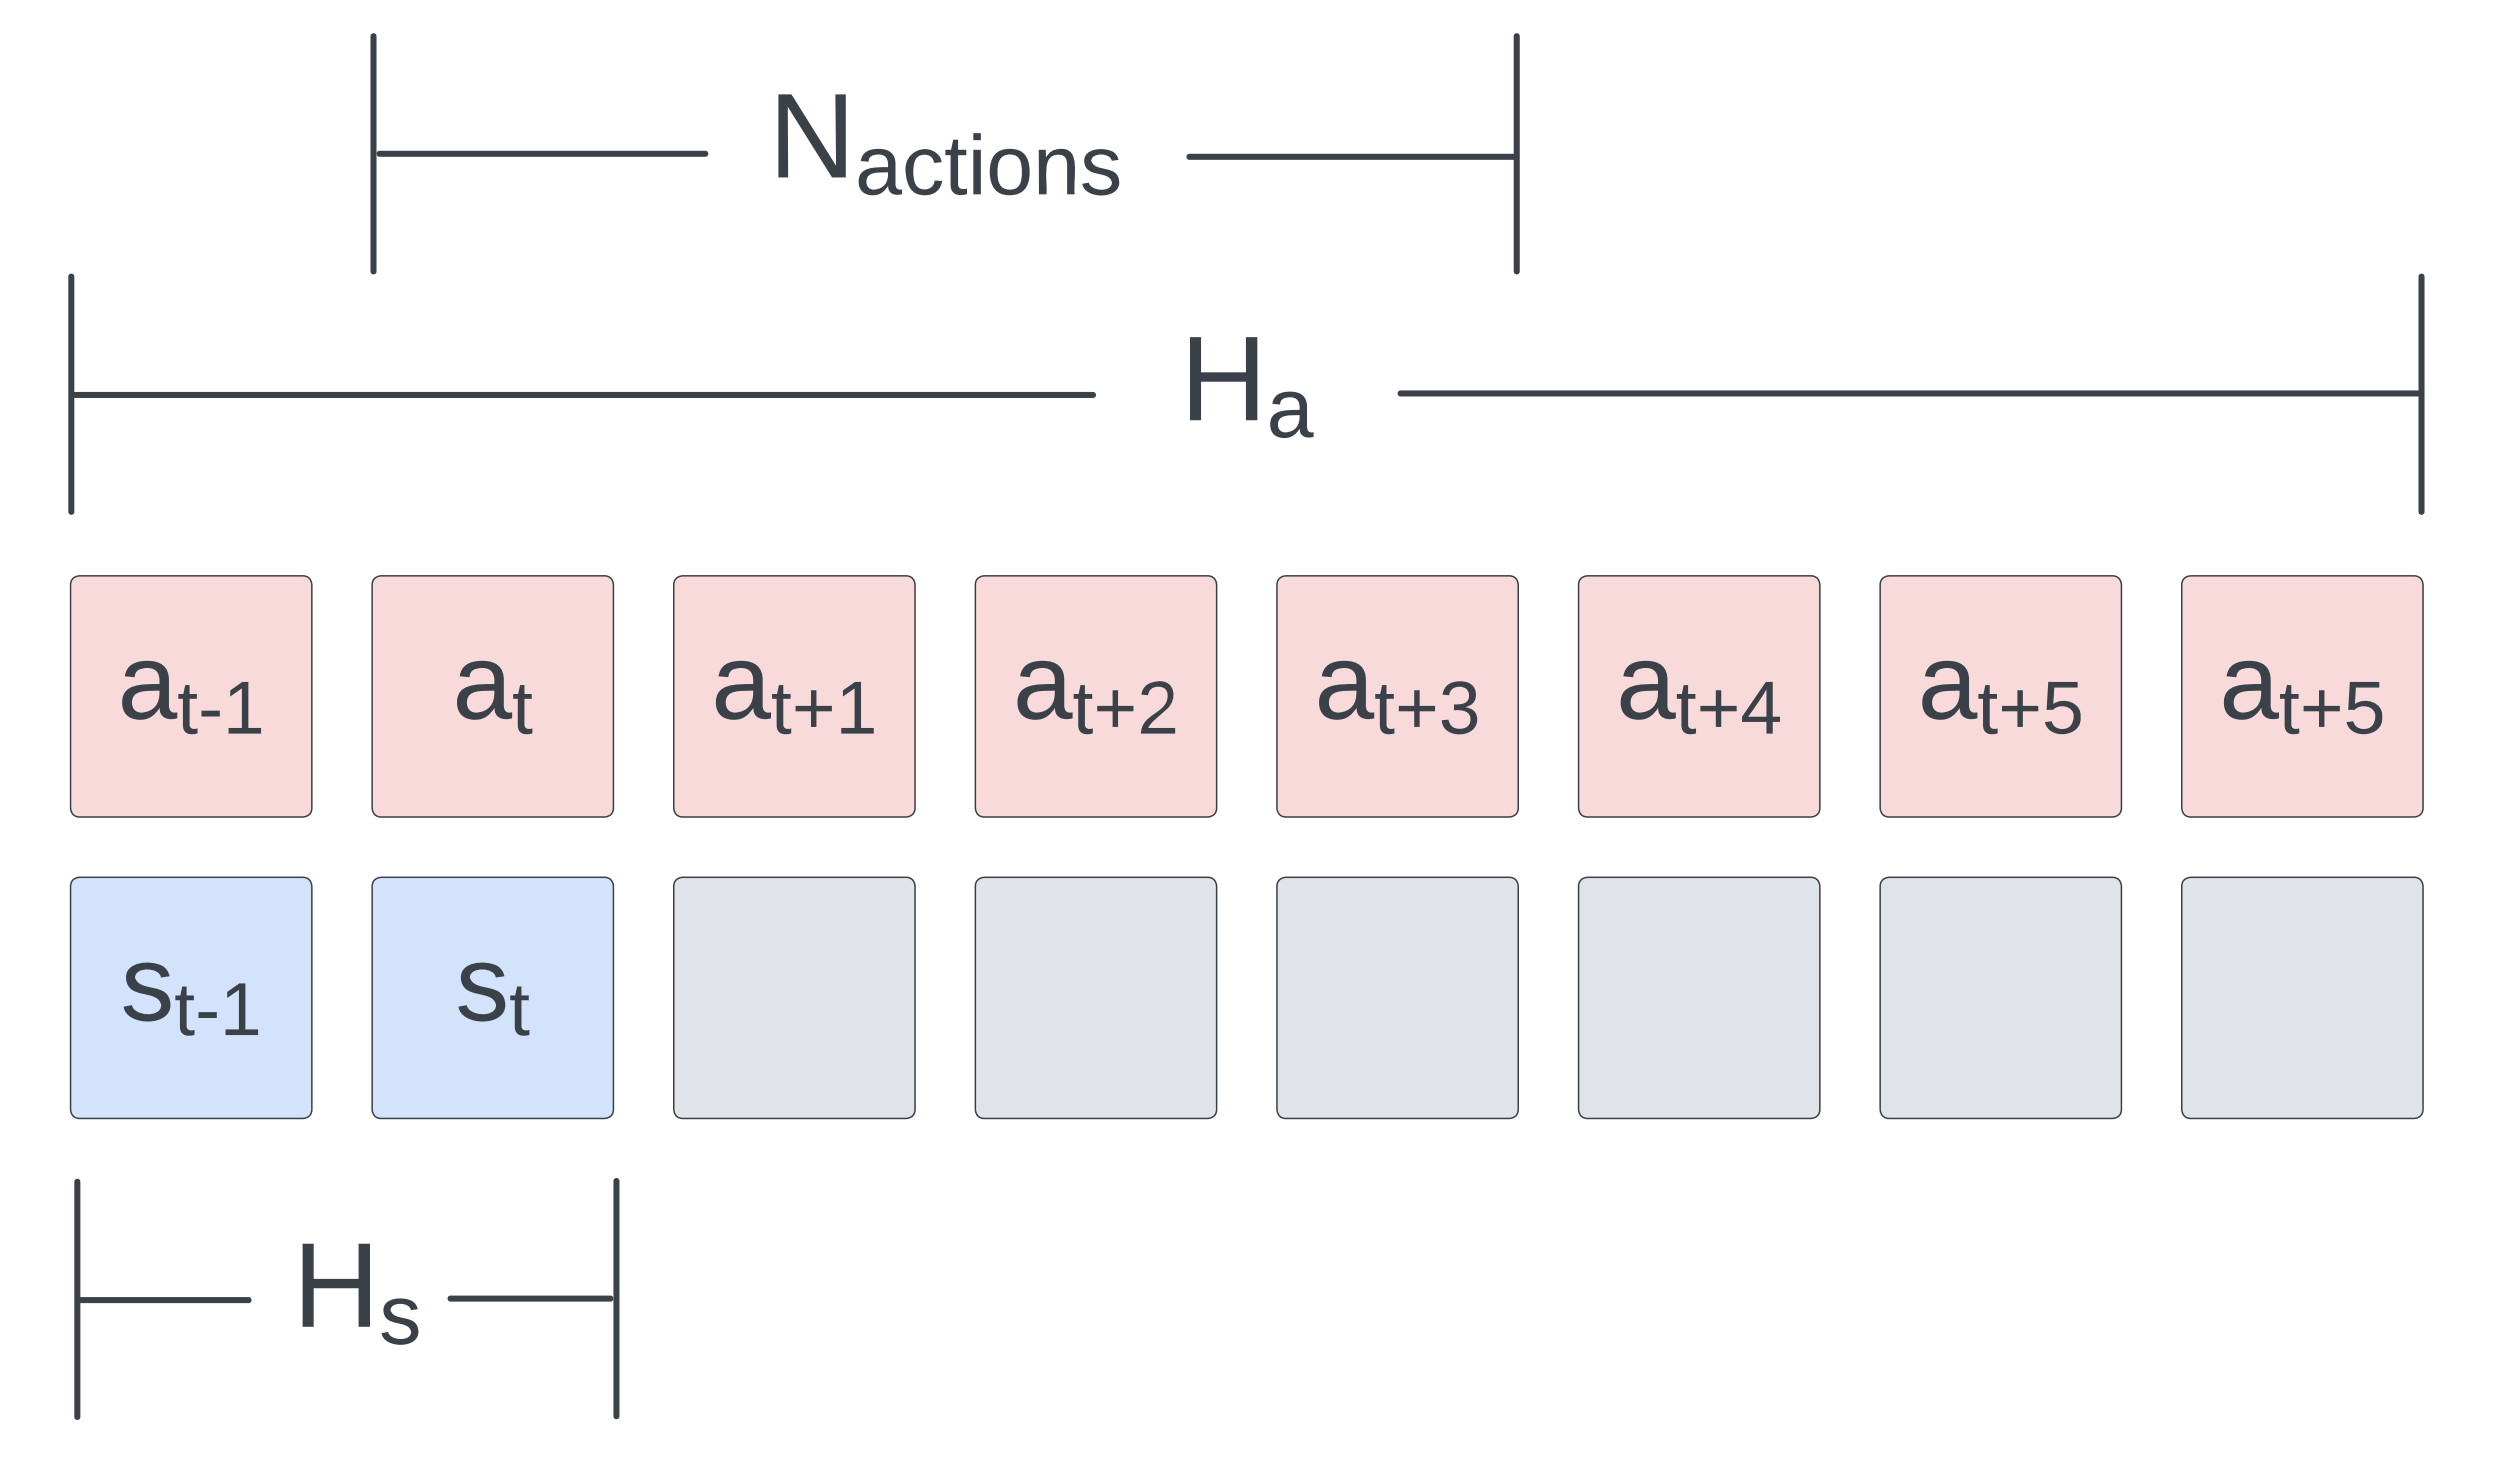

*TODO:* Complete implementation of ``run_rollout`` in ``robotics/runner.py`` \
*Note:* We want the guidance weight to be zero

_Hint:_ We generate $H_a$ actions at a time, and carry out $N_{actions}$ of those actions.  So you should not actually be generating actions at every timestep

In [39]:
# generate rollout

import importlib
import robotics.runner
importlib.reload(robotics.runner)
from robotics.runner import EnvRunner

runner = EnvRunner()
runner.load_data(dataset_path='robotics/push_t_dataset.zarr/', batch_size=256)
runner.policy.load_weights('model_pths/robotics_weights.pth')

imgs, max_images = runner.run_rollout()


number of parameters: 6.535322e+07


Eval PushTStateEnv:  84%|████████▎ | 209/250 [00:27<00:05,  7.57it/s, reward=1]

Max reward: 1.0


The 2 points for this section will be graded based on `Max reward`:

| Max Reward | Points  |
|------------|---------|
| ≥ 0.3      | 0.25 pt |
| ≥ 0.4      | 0.5 pt  |
| ≥ 0.5      | 1 pt    |
| ≥ 0.7      | 2 pt    |

There is definitely an element of randomization with diffusion models, so if the movement is reasonable feel free to run the rollout again or train for a little longer.

In [40]:
# Video of the rollout to help you debug
import imageio.v2 as imageio
from IPython.display import Video
imageio.mimsave('vis.mp4', imgs, fps=10)
Video('vis.mp4', embed=True, width=256, height=256)

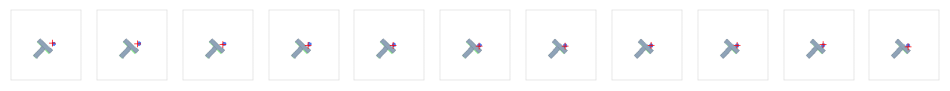

In [41]:
# Images of the timesteps leading up to max reward (so we can see that it did not just randomly reach the goal)

# Plot images in a row
from matplotlib import pyplot as plt
fig, axes = plt.subplots(1, len(max_images), figsize=(12, 8))
for i in range(len(max_images)):
    axes[i].imshow(max_images[i])
    axes[i].axis('off')

# Part 3 - Experiments [Extra Credit - 1 point max]

This section is very open ended, it is your chance to experiment with the models you have created (in image generation or robotics) and earn some extra credit points.  Be creative!  We are looking for interesting analysis and visualization.  The more effort you put into this section, the more points you can get.
\
\
Suggestions for conducting a good experiment:
- Be systematic and scientific
    - Clearly state the variable you will changing
    - Define an evaluation metric
    - Come up with a hypotheses (why might changing these values even matter)?
    - Do a reasonable sweep over parameter values (does not need to be too extensive)
- Visualizations
    - Graphs, pictures, and rollout videos are easier to digest than tables of numbers
- Analysis
    - Don't just report the results, think about what they mean
    - Is the behavior what you expected?
    - What additional questions does this leave you with?
    - What did you learn (even if your experiment failed or is only partially completed)?

# Homework 4 Writeup

- Name: `Venkata Aashutosh Aripirala`
- GT Email: `av84`
- GT ID: `904173725`

Please refer to the original section for more context on the questions if needed. Write your answers where indicated.

### 2.1.1 Forward Process [0.5 point]
What does $q(x_t|x_o)$ represent for a diffusion model? (read the paper provided in this section)

### Answer:


$q(x_t|x_o)$ represents the marginal distribution of the latent state at arbitrary timestep t conditioned directly on the original, uncorrupted data point $x_0$.


Mathematically, it allows jumping directly to step t in closed form without having to iteratively sample intermediate steps $x_1, ..., x_(t-1)$:

$q(\mathbf{x}_t \mid \mathbf{x}_0) = N\left(\mathbf{x}_t; \sqrt{\bar{\alpha}_t} \mathbf{x}_0, (1 - \bar{\alpha}_t)\mathbf{I}\right)$

where $\alpha_t = 1 - \beta_t$ and $\bar{\alpha}_t = \prod_{s=1}^t \alpha_s$. It formalizes the cumulative forward diffusion process as scaling the original sample by $\sqrt{\bar{\alpha}_t}$ while injecting Gaussian noise with variance $(1 - \bar{\alpha}_t)\mathbf{I}$.


### 2.2.1 Compute Loss for Training [0.5 point]
What is $\epsilon_\theta(\sqrt{\bar{\alpha_t}}x_0 + \sqrt{1 - \bar{\alpha_t}}\epsilon, t)$ ?


### Answer
$\boldsymbol{\epsilon}_\theta(\sqrt{\bar{\alpha}_t}\mathbf{x}_0 + \sqrt{1 - \bar{\alpha}_t}\boldsymbol{\epsilon}, t)$ represents the neural network's prediction of the standard Gaussian noise $\boldsymbol{\epsilon}$ that was added to corrupt the clean data $\mathbf{x}_0$ into the noisy sample $\mathbf{x}_t$ at timestep $t$.

The input $\sqrt{\bar{\alpha}_t}\mathbf{x}_0 + \sqrt{1 - \bar{\alpha}_t}\boldsymbol{\epsilon}$ is the closed-form noisy latent $\mathbf{x}_t$ sampled from the forward diffusion distribution $q(\mathbf{x}_t \mid \mathbf{x}_0)$.

${\epsilon}_\theta$ is a parameterized function approximator trained to estimate the exact noise vector ${\epsilon} \sim N(\mathbf{0}, \mathbf{I})$ used in that forward step.By predicting $\boldsymbol{\epsilon}$, the network effectively learns the score function $\nabla_{\mathbf{x}_t} \log p_t(\mathbf{x}_t)$, which enables reversing the diffusion process to denoise $\mathbf{x}_t$ back toward $\mathbf{x}_0$.

### 2.3.1 Image Generation and Classifier Free Guidance [3 points]
What do you notice about the quality of unguided image generation?  How effectively is the model learning each class? This is very early in the training process, but do you notice any features that the model is learning for each class?

### Answer

The unguided generations are blurry and lack fine details, but the model is already capturing global features for several classes. Like for airplanes, dominant light blue/white palettes representing sky and clouds, with dark, horizontal silhouettes centered in the frame; for automobiles ground-level horizontal blocks with darker lower halves and distinct color contrasts between the vehicle body and background;   for birds, green/blue backgrounds representing foliage or sky, with small, centered dark spots representing the animal silhouette. While it can't yet render high-frequency textures, it has effectively learned class-specific color distributions and coarse geometric layouts.

Explain why we dont have to retrain for image guidance.

### Answer

We train a single model to handle both conditional and unconditional generation simultaneously. By randomly dropping the class conditioning label with probability $p_{\text{uncond}}$ (replacing it with a null token $\emptyset$), the network learns to approximate both $\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t, c)$ and $\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t, \emptyset)$. At inference, classifier-free guidance simply takes a linear combination of these two forward outputs:$$\tilde{\boldsymbol{\epsilon}}_\theta = (1 + w)\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t, c) - w\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t, \emptyset)$$Because both predictions come from the same network weights, adjusting the guidance strength $w$ requires no retraining.

What do you notice about the generations with classifier free guidance?  What features does the model pick up as being most indicattive of each class?  Does performance degrade as guidance increases? If so, how?


### Answer

Adding classifier-free guidance significantly enhances class-specific contrast and foreground definition. The model focuses heavily on salient identifying traits—such as wing contrast against skies for planes, wheels and chassis profiles for cars, and centered animal bodies on contrasting foliage.   Regarding degradation at high guidance,  yes, performance degrades when guidance becomes too large ($w \gg 1$). Because CFG extrapolates beyond the training distribution, extreme weights cause sample values to exceed the normalized $[-1, 1]$ bounds. This leads to severe over-saturation, harsh contrast artifacts and a dramatic drop in sample diversity.

### 2.3.2 Thresholding [3 points]

Why shouldn't we just threshold $x_{t-1}$ to be within [-1, 1]?

### Answer

$x_{t-1}$ contains Gaussian noise that naturally extends beyond $[-1, 1]$. Clamping $x_{t-1}$ directly distorts this noise distribution and breaks the reverse process. Only clean data $x_0$ belongs in $[-1, 1]$, so we estimate and clamp $\hat{x}_0$ instead.

Additionally, why is thresholding particularly useful when dealing with large guidance weights?

### Answer

High guidance weights aggressively extrapolate predictions, pushing values far outside $[-1, 1]$. Thresholding clips these extreme predictions at each step, preventing accumulated errors that cause severe oversaturation and blown-out colors.

How do the results after thresholding compare to the results before thresholding?

### Answer

Before thresholding, images at high guidance become harsh, overexposed, and blown out with clipping artifacts. After thresholding, images retain relatively sharper class features and high contrast without color blowouts or extreme saturation.  

### 2.4.2 Generating a Rollout [Extra Credit - 1 point]
What did you learn from training this model?  Did you notice any interesting behavior?  Even if you never got a high reward, where did you notice the agent failing?

### Answer

Training demonstrated that diffusion models handle multimodal action distributions smoothly, using action chunking ($H_a$) and receding-horizon control to execute human-like fluid trajectories rather than jittery single-step reactions.

In our rollout as seen in the generated video, the agent displayed goal-directed movement, navigating straight to the T-block and pivoting its corners to achieve complete alignment (reward = 1.0). I think  the policy can fail in cases when, it struggles with rotational precision near goal boundaries, improper contact angles can slide the block into out-of-distribution states that are hard to recover from.

#### Collect Submission

Run the following cell to collect ```hw4_code_submission.zip```.  You will submit this to `HW4-Code: Diffusion Models` on gradescope.  Make sure to also export a PDF of this jupyter notebook and submit it to `HW4-Writeup: Diffusion Models`.  This PDF must show your answers to all the questions in the document, please leave in all the photos that you generate as well.  You will not be given credit for anything that is not visible to us in this PDF.

In [ ]:
# on colab, you may need to install chromium to convert the notebook to pdf
!playwright install-deps chromium
!playwright install chromium

In [43]:
!python ./collect_submission.py

=== HW4 Submission Collection Script ===

Converting notebook to PDF...
Successfully converted main.ipynb to hw4_notebook_submission.pdf

Creating zip archive...
Created hw4_code_submission.zip

=== Submission Collection Complete ===
Generated: hw4_notebook_submission.pdf
Generated: hw4_code_submission.zip

Please submit these files to Gradescope:
  - hw4_notebook_submission.pdf
  - hw4_code_submission.zip

Congratulations on completing the assignment!


*Contributors*
- Matthew Bronars (Lead)
- Manav Agrawal
- Mihir Bafna